<a href="https://colab.research.google.com/github/kushal984762333-glitch/ibm-ds-capstone-spacex/blob/main/05-eda-dataviz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 - EDA with Data Visualization

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/dataset_part_2.csv')
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


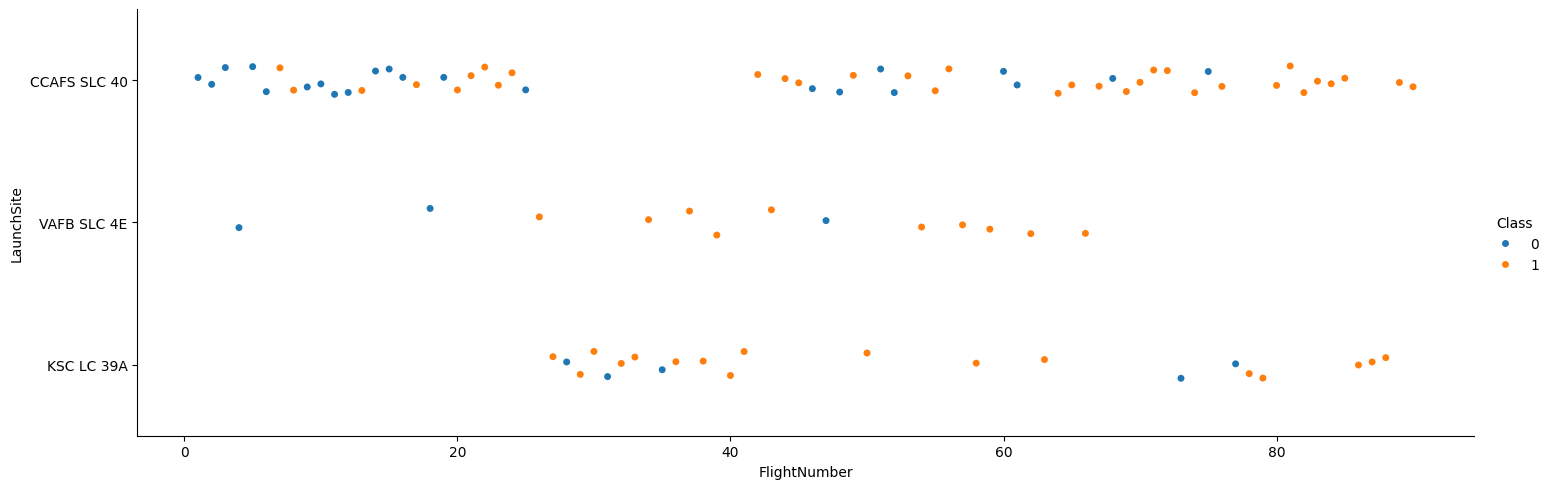

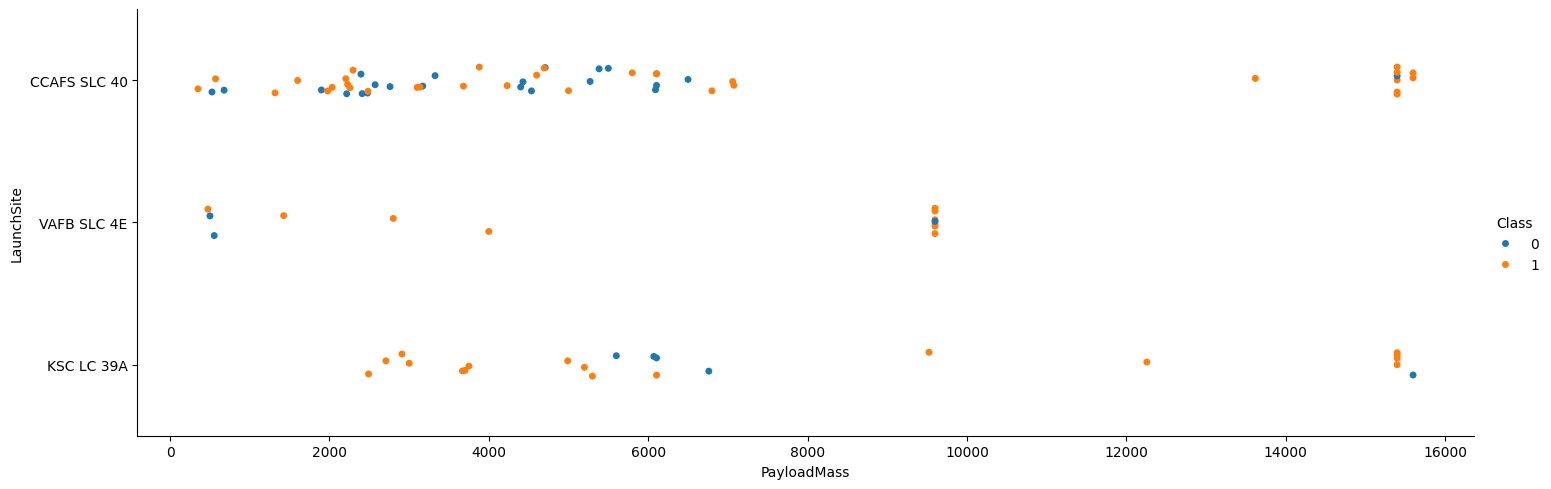

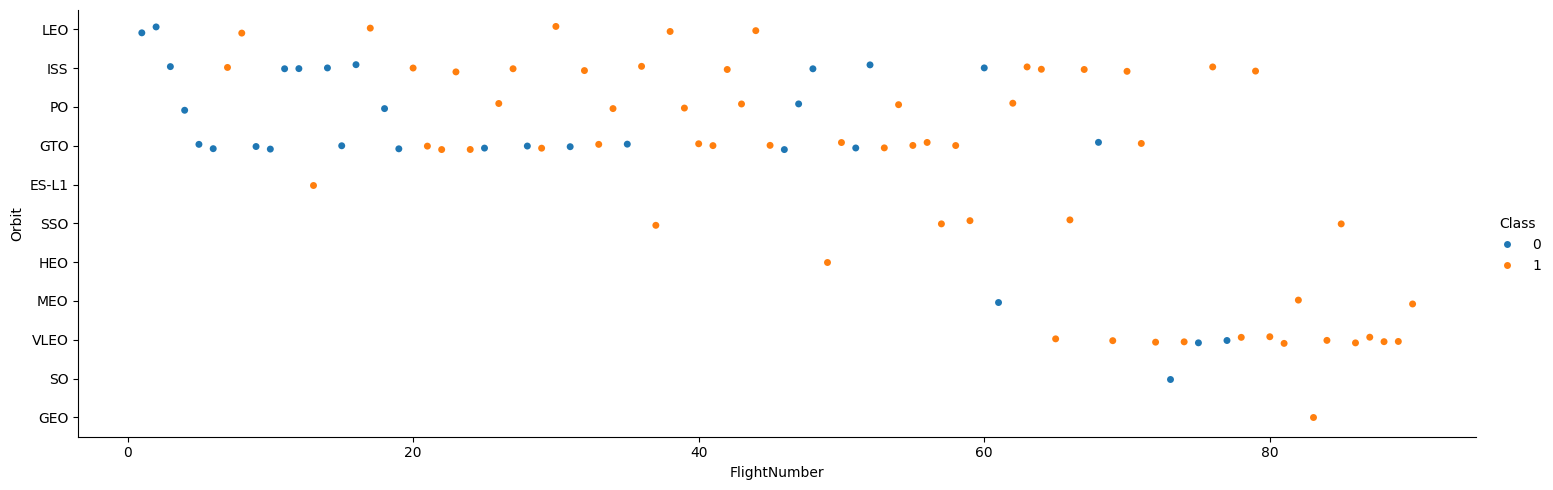

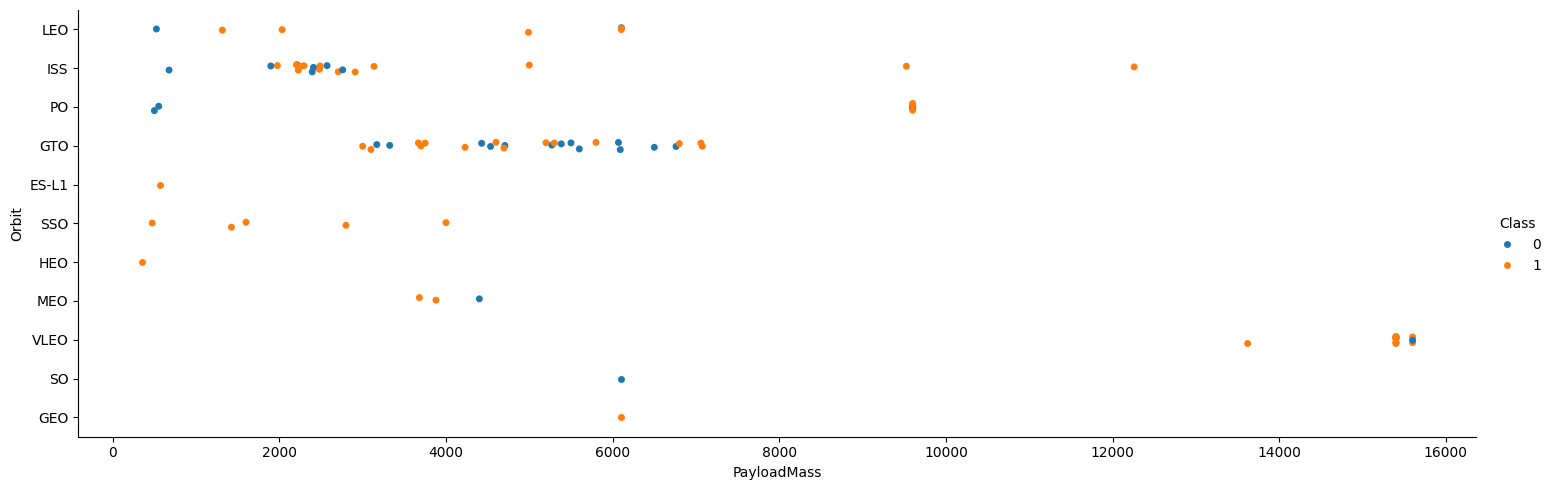

In [2]:
for x,y,f in [('FlightNumber','LaunchSite','flight_vs_site'),('PayloadMass','LaunchSite','payload_vs_site'),('FlightNumber','Orbit','flight_vs_orbit'),('PayloadMass','Orbit','payload_vs_orbit')]:
    sns.catplot(y=y,x=x,hue='Class',data=df,aspect=3)
    plt.savefig(f+'.png',dpi=150,bbox_inches='tight'); plt.show()

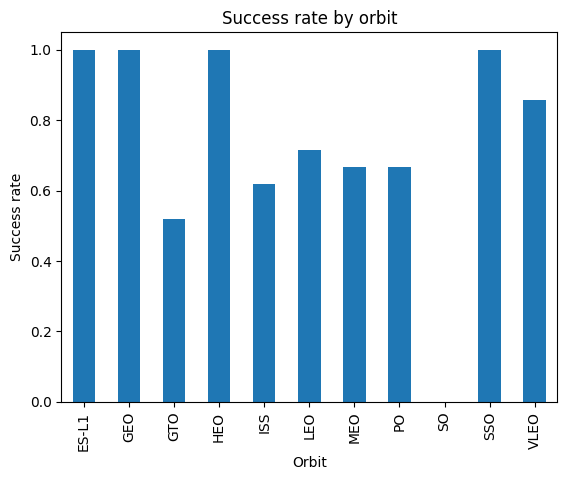

In [3]:
df.groupby('Orbit')['Class'].mean().plot(kind='bar',title='Success rate by orbit');plt.ylabel('Success rate');plt.show()

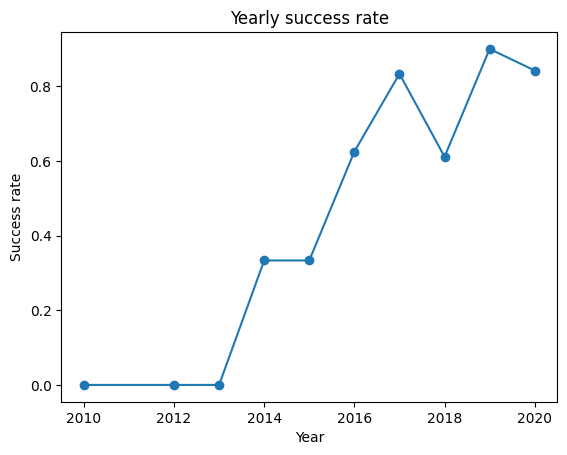

In [4]:
df['Year']=pd.to_datetime(df['Date']).dt.year
df.groupby('Year')['Class'].mean().plot(marker='o',title='Yearly success rate');plt.ylabel('Success rate');plt.show()

In [5]:
features=df[['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']]
features_one_hot=pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial']).astype('float64')
features_one_hot.to_csv('dataset_part_3.csv',index=False)